# Univariate Feature Selection: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/feature_selection/plot_feature_selection.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/feature_selection/plot_feature_selection.html)).

**Scenario:** the iris data with 20 uniform noise features appended. `SelectKBest(f_classif, k=4)` scores
every feature (`-log10(pvalues_)`), then `MinMaxScaler + LinearSVC` is trained with and without the
selector in front, and the SVM weights are compared.

**Adaptations:**
- Bundled iris data and the example's seeded noise are created in Python and shared with Moxie.
- Moxie `LinearSVC` takes typed `List[Float64]` labels, while the univariate scorers take an `NDArray`
  target. The example's `make_pipeline(SelectKBest(...), MinMaxScaler(), LinearSVC())` therefore cannot be
  expressed as one Moxie `Pipeline` (see the `GAP` cell); the Moxie program chains the same fitted steps
  explicitly (`fit_transform` of each transformer, then `fit` of the classifier), which is exactly what
  the pipeline does on fit and predict.
- Beyond the example, the notebook checks the other univariate selectors (`SelectPercentile`, `SelectFpr`,
  `SelectFdr`, `SelectFwe`, `GenericUnivariateSelect` in every mode, plus `chi2` on the non-negative data),
  `get_support`, `inverse_transform`, `get_feature_names_out` and `VarianceThreshold` on the same data.

**Determinism:** deterministic (fixed seeds; `LinearSVC` with `dual="auto"` solves the primal problem with a
deterministic Newton method on this tall data set).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("feature_selection/plot_feature_selection")

## 1. scikit-learn (Python reference)

The official example code (figures shrunk).

In [2]:
import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

X, y = load_iris(return_X_y=True)
E = np.random.RandomState(42).uniform(0, 0.1, size=(X.shape[0], 20))
X = np.hstack((X, E))
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=0)

from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(f_classif, k=4)
selector.fit(X_train, y_train)
scores = -np.log10(selector.pvalues_)
scores /= scores.max()

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import LinearSVC

clf = make_pipeline(MinMaxScaler(), LinearSVC())
clf.fit(X_train, y_train)
print("Classification accuracy without selecting features: {:.3f}".format(clf.score(X_test, y_test)))
svm_weights = np.abs(clf[-1].coef_).sum(axis=0)
svm_weights /= svm_weights.sum()

clf_selected = make_pipeline(SelectKBest(f_classif, k=4), MinMaxScaler(), LinearSVC())
clf_selected.fit(X_train, y_train)
print("Classification accuracy after univariate feature selection: {:.3f}".format(clf_selected.score(X_test, y_test)))
svm_weights_selected = np.abs(clf_selected[-1].coef_).sum(axis=0)
svm_weights_selected /= svm_weights_selected.sum()

Classification accuracy without selecting features: 0.789
Classification accuracy after univariate feature selection: 0.868


Reference values for the additional selectors and mapping methods.

In [3]:
from sklearn.feature_selection import (SelectPercentile, SelectFpr, SelectFdr, SelectFwe,
                                       GenericUnivariateSelect, VarianceThreshold, chi2)
names = np.array([f"f{i}" for i in range(X.shape[1])], dtype=object)
ref = {}
ref["kbest_scores"], ref["kbest_pvalues"] = selector.scores_, selector.pvalues_
ref["kbest_support"] = selector.get_support(indices=True)
ref["kbest_transform"] = selector.transform(X_test)
ref["kbest_inverse"] = selector.inverse_transform(selector.transform(X_test))
ref["percentile_support"] = SelectPercentile(f_classif, percentile=10).fit(X_train, y_train).get_support()
ref["fpr_support"] = SelectFpr(f_classif, alpha=0.05).fit(X_train, y_train).get_support()
ref["fdr_support"] = SelectFdr(f_classif, alpha=0.01).fit(X_train, y_train).get_support()
ref["fwe_support"] = SelectFwe(f_classif, alpha=0.01).fit(X_train, y_train).get_support()
for mode, param in [("percentile", 25), ("k_best", 3), ("fpr", 1e-3), ("fdr", 1e-3), ("fwe", 1e-3)]:
    ref[f"generic_{mode}"] = GenericUnivariateSelect(f_classif, mode=mode, param=param).fit(X_train, y_train).get_support()
chi = SelectKBest(chi2, k=4).fit(X_train, y_train)
ref["chi2_scores"], ref["chi2_pvalues"], ref["chi2_support"] = chi.scores_, chi.pvalues_, chi.get_support()
vt = VarianceThreshold(threshold=0.01).fit(X_train)
ref["vt_variances"], ref["vt_support"] = vt.variances_, vt.get_support()
named = SelectKBest(f_classif, k=4).fit(
    __import__("pandas").DataFrame(X_train, columns=names), y_train)
ref["names_out"] = named.get_feature_names_out()
ref["svm_coef"] = clf[-1].coef_
ref["svm_coef_selected"] = clf_selected[-1].coef_
ref["pred"] = clf.predict(X_test)
ref["pred_selected"] = clf_selected.predict(X_test)
nb.share(X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test, names=names.astype(str))

## 2. Moxie (native Mojo)

In [4]:
%%mojo univariate_selection
import numojo as nm
from moxie.feature_selection import (
    SelectKBest, SelectPercentile, SelectFpr, SelectFdr, SelectFwe, GenericUnivariateSelect,
    VarianceThreshold, BuiltinScorer, SelectionParameter,
)
from moxie.preprocessing import MinMaxScaler
from moxie.svm import LinearSVC
from moxie_nb_io import load, load_strings, save, save_ints, save_floats, save_strings


def labels(y: nm.NDArray[DType.float64]) raises -> List[Float64]:
    var out = List[Float64]()
    for i in range(y.shape[0]):
        out.append(Float64(y.item(i)))
    return out^


def mask_ints(mask: List[Bool]) -> List[Int]:
    var out = List[Int]()
    for m in mask:
        out.append(Int(m))
    return out^


def main() raises:
    var X_train = load("X_train")
    var y_train = load("y_train")
    var X_test = load("X_test")
    var y_test = load("y_test")
    var names = load_strings("names")

    var selector = SelectKBest(BuiltinScorer("f_classif"), k=SelectionParameter(4))
    _ = selector.fit(X_train, y_train.copy())
    save("kbest_scores", selector.scores_())
    save("kbest_pvalues", selector.pvalues_().value())
    save_ints("kbest_support", selector.get_support(True)[List[Int]].copy())
    var selected_test = selector.transform(X_test)
    save("kbest_transform", selected_test)
    save("kbest_inverse", selector.inverse_transform(selected_test))

    var percentile = SelectPercentile(BuiltinScorer("f_classif"), percentile=10)
    _ = percentile.fit(X_train, y_train.copy())
    save_ints("percentile_support", mask_ints(percentile.get_support()[List[Bool]].copy()))
    var fpr = SelectFpr(BuiltinScorer("f_classif"), alpha=0.05)
    _ = fpr.fit(X_train, y_train.copy())
    save_ints("fpr_support", mask_ints(fpr.get_support()[List[Bool]].copy()))
    var fdr = SelectFdr(BuiltinScorer("f_classif"), alpha=0.01)
    _ = fdr.fit(X_train, y_train.copy())
    save_ints("fdr_support", mask_ints(fdr.get_support()[List[Bool]].copy()))
    var fwe = SelectFwe(BuiltinScorer("f_classif"), alpha=0.01)
    _ = fwe.fit(X_train, y_train.copy())
    save_ints("fwe_support", mask_ints(fwe.get_support()[List[Bool]].copy()))
    var modes = ["percentile", "k_best", "fpr", "fdr", "fwe"]
    var params = [SelectionParameter(Float64(25)), SelectionParameter(3), SelectionParameter(Float64(1e-3)),
                  SelectionParameter(Float64(1e-3)), SelectionParameter(Float64(1e-3))]
    for i in range(5):
        var generic = GenericUnivariateSelect(BuiltinScorer("f_classif"), mode=modes[i], param=params[i].copy())
        _ = generic.fit(X_train, y_train.copy())
        save_ints("generic_" + modes[i], mask_ints(generic.get_support()[List[Bool]].copy()))

    var chi = SelectKBest(BuiltinScorer("chi2"), k=SelectionParameter(4))
    _ = chi.fit(X_train, y_train.copy())
    save("chi2_scores", chi.scores_())
    save("chi2_pvalues", chi.pvalues_().value())
    save_ints("chi2_support", mask_ints(chi.get_support()[List[Bool]].copy()))

    var vt = VarianceThreshold(threshold=0.01)
    _ = vt.fit(X_train)
    save("vt_variances", vt.variances_())
    save_ints("vt_support", mask_ints(vt.get_support()[List[Bool]].copy()))

    var named = SelectKBest(BuiltinScorer("f_classif"), k=SelectionParameter(4))
    named.fit_named(X_train, y_train.copy(), names)
    save_strings("names_out", named.get_feature_names_out())

    # make_pipeline(MinMaxScaler(), LinearSVC()), chained explicitly.
    var y_fit = labels(y_train)
    var y_eval = labels(y_test)
    var scaler = MinMaxScaler()
    var scaled_train = scaler.fit_transform(X_train)
    var svm = LinearSVC()
    _ = svm.fit(scaled_train, y_fit)
    var scaled_test = scaler.transform(X_test)
    print("Classification accuracy without selecting features:", svm.score(scaled_test, y_eval))
    save("svm_coef", svm.coef_)
    save_floats("pred", svm.predict(scaled_test))

    # make_pipeline(SelectKBest(f_classif, k=4), MinMaxScaler(), LinearSVC()), chained explicitly.
    var pipe_selector = SelectKBest(BuiltinScorer("f_classif"), k=SelectionParameter(4))
    var reduced_train = pipe_selector.fit_transform(X_train, y_train.copy())
    var pipe_scaler = MinMaxScaler()
    var reduced_scaled = pipe_scaler.fit_transform(reduced_train)
    var svm_selected = LinearSVC()
    _ = svm_selected.fit(reduced_scaled, y_fit)
    var reduced_test = pipe_scaler.transform(pipe_selector.transform(X_test))
    print("Classification accuracy after univariate feature selection:", svm_selected.score(reduced_test, y_eval))
    save("svm_coef_selected", svm_selected.coef_)
    save_floats("pred_selected", svm_selected.predict(reduced_test))

Classification accuracy without selecting features: 0.7894736842105263
Classification accuracy after univariate feature selection: 0.868421052631579


The example's single pipeline object, written with Moxie's `Pipeline`. It does not compile because the selector's `NDArray` target and `LinearSVC`'s `List[Float64]` target differ:

In [5]:
%%mojo pipeline_selectkbest_linearsvc --expect-fail
from moxie.pipeline import Pipeline
from moxie.feature_selection import SelectKBest, BuiltinScorer, SelectionParameter
from moxie.preprocessing import MinMaxScaler
from moxie.svm import LinearSVC
from moxie_nb_io import load


def main() raises:
    var X_train = load("X_train")
    var y_train = load("y_train")
    var pipe = Pipeline(SelectKBest(BuiltinScorer("f_classif"), k=SelectionParameter(4)),
                        Pipeline(MinMaxScaler(), LinearSVC()))
    _ = pipe.fit(X_train, y_train)

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/feature_selection/plot_feature_selection/pipeline_selectkbest_linearsvc.mojo:13:27: error: invalid call to 'fit': value passed to 'y' cannot be converted from 'NDArray' to ref 'Pipeline[SelectKBest, Pipeline[MinMaxScaler, LinearSVC]].Target'
    _ = pipe.fit(X_train, y_train)
        ~~~~~~~~          ^~~~~~~
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/feature_selection/plot_feature_selection/pipeline_selectkbest_linearsvc.mojo:13:27: note: operand element type 'NDArray' doesn't match expected element type 'Pipeline[SelectKBest, Pipeline[MinMaxScaler, LinearSVC]].Target'
    _ = pipe.fit(X_train, y_train)
                          ^
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/feature_selection/plot_feature_selection/pipeline_selectkbest_linearsvc.mojo:1:
Imported from /

## 3. Side by side and parity

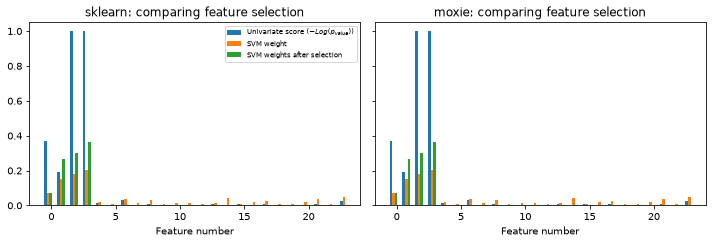

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
SelectKBest scores_,PASS,"(24,)","(24,)",0,0,"rtol=1e-10, atol=0",,Float64 one-way ANOVA; sum-of-squares reduction order differs from NumPy
SelectKBest pvalues_,PASS,"(24,)","(24,)",8.83e-15,3.04e-14,"rtol=1e-11, atol=1e-300",,"native F tail (Lentz continued fraction, Numax libm exp/log) vs scipy fdtrc: ~1e-13 relative; score rounding amplified by |dlog p/dlog F|"
normalised -log10(pvalues) (plot),PASS,"(24,)","(24,)",2.06e-16,2.46e-14,"rtol=1e-09, atol=0",,log of the p-values above
SelectKBest get_support(indices=True),PASS,"(4,)","(4,)",,,exact,0 mismatches,
SelectKBest transform,PASS,"(38, 4)","(38, 4)",,,exact,0 mismatches,
SelectKBest inverse_transform,PASS,"(38, 24)","(38, 24)",,,exact,0 mismatches,
get_feature_names_out,PASS,"(4,)","(4,)",,,exact,0 mismatches,
percentile_support,PASS,"(24,)","(24,)",,,exact,0 mismatches,
fpr_support,PASS,"(24,)","(24,)",,,exact,0 mismatches,
fdr_support,PASS,"(24,)","(24,)",,,exact,0 mismatches,


In [6]:
import matplotlib.pyplot as plt
mx = nb.results["univariate_selection"]
mx_scores = -np.log10(mx["kbest_pvalues"]); mx_scores /= mx_scores.max()
mx_w = np.abs(mx["svm_coef"]).sum(axis=0); mx_w /= mx_w.sum()
mx_ws = np.abs(mx["svm_coef_selected"]).sum(axis=0); mx_ws /= mx_ws.sum()
X_indices = np.arange(X.shape[-1])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), dpi=72, sharey=True)
for ax, label, s, w, ws, support in [
        (axes[0], "sklearn", scores, svm_weights, svm_weights_selected, selector.get_support()),
        (axes[1], "moxie", mx_scores, mx_w, mx_ws, np.isin(X_indices, mx["kbest_support"]))]:
    ax.bar(X_indices - 0.45, s, width=0.2, label=r"Univariate score ($-Log(p_{value})$)")
    ax.bar(X_indices - 0.25, w, width=0.2, label="SVM weight")
    ax.bar(X_indices[support] - 0.05, ws, width=0.2, label="SVM weights after selection")
    ax.set_title(f"{label}: comparing feature selection"); ax.set_xlabel("Feature number")
axes[0].legend(loc="upper right", fontsize=7)
plt.tight_layout(); plt.show()
moxie_nb.side_by_side(sklearn=scores[:6], moxie=mx_scores[:6])

nb.compare("SelectKBest scores_", ref["kbest_scores"], mx["kbest_scores"], rtol=1e-10,
           reason="Float64 one-way ANOVA; sum-of-squares reduction order differs from NumPy")
nb.compare("SelectKBest pvalues_", ref["kbest_pvalues"], mx["kbest_pvalues"], rtol=1e-11, atol=1e-300,
           reason="native F tail (Lentz continued fraction, Numax libm exp/log) vs scipy fdtrc: ~1e-13 relative; score rounding amplified by |dlog p/dlog F|")
nb.compare("normalised -log10(pvalues) (plot)", scores, mx_scores, rtol=1e-9, reason="log of the p-values above")
nb.compare("SelectKBest get_support(indices=True)", ref["kbest_support"], mx["kbest_support"], exact=True)
nb.compare("SelectKBest transform", ref["kbest_transform"], mx["kbest_transform"], exact=True)
nb.compare("SelectKBest inverse_transform", ref["kbest_inverse"], mx["kbest_inverse"], exact=True)
nb.compare("get_feature_names_out", ref["names_out"].astype(str), mx["names_out"], exact=True)
for key in ["percentile_support", "fpr_support", "fdr_support", "fwe_support"] + [
        f"generic_{m}" for m in ["percentile", "k_best", "fpr", "fdr", "fwe"]]:
    nb.compare(key, ref[key].astype(int), mx[key], exact=True)
nb.compare("chi2 scores_", ref["chi2_scores"], mx["chi2_scores"], rtol=1e-10, reason="Float64 chi-square sums")
nb.compare("chi2 pvalues_", ref["chi2_pvalues"], mx["chi2_pvalues"], rtol=1e-11, atol=1e-300, reason="native chi-square tail (series/continued fraction, Numax libm) vs scipy chdtrc")
nb.compare("chi2 support", ref["chi2_support"].astype(int), mx["chi2_support"], exact=True)
nb.compare("VarianceThreshold variances_", ref["vt_variances"], mx["vt_variances"], rtol=1e-10, reason="population variance, reduction order")
nb.compare("VarianceThreshold support", ref["vt_support"].astype(int), mx["vt_support"], exact=True)
nb.compare("LinearSVC coef_ (all features)", ref["svm_coef"], mx["svm_coef"], rtol=1e-5, atol=1e-6,
           reason="LinearSVC (svm family) stops its primal trust-region Newton solver at tol=1e-4; reduction-order differences move the stopping iterate by ~5e-8 absolute; predictions are compared exactly")
nb.compare("LinearSVC coef_ (after SelectKBest)", ref["svm_coef_selected"], mx["svm_coef_selected"], rtol=1e-5, atol=1e-6, reason="as above")
nb.compare("predict (all features)", ref["pred"], mx["pred"], exact=True)
nb.compare("predict (after SelectKBest)", ref["pred_selected"], mx["pred_selected"], exact=True)
nb.note("make_pipeline(SelectKBest, MinMaxScaler, LinearSVC)", "GAP",
        "Moxie Pipeline needs one target type; univariate scorers take NDArray targets, LinearSVC takes List[Label]. Steps chained explicitly above.")
nb.report()
nb.assert_parity()